# [GSE192440](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE192440)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2023-11-11
> - Modified: 2025-07-20

# 1. Experimental Design

> RNA m6A methylome in mouse oocytes and preimplantation embryos.
> - Wang, Y., Li, Y., Skuland, T. et al. The RNA m6A landscape of mouse oocytes and preimplantation embryos. Nat Struct Mol Biol 30, 703–709 (2023). https://doi.org/10.1038/s41594-023-00969-x.
> - picoMeRIP-seq
> - Illumina NovaSeq, PE100
> - mm10

In [1]:
library(tidyverse)
suppressPackageStartupMessages({
    library(rtracklayer)
    library(GenomicRanges)
    library(GenomeInfoDb)
    library(RColorBrewer)
    library(viridis)
    library(cowplot)
})

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/meripseq_Mm_Embryos_Diff_GSE192440/02_output"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"

suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

In [3]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 2. Data Import

## 1). narrowPeak Import

In [4]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [5]:
peaks_files1 <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "_m6A_peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_m6A_peaks\\.narrowPeak$", "\\1_macs2", basename(.x)))

peaks_files2 <- file.path(data_dir, "05_exomePeak2") |>
    list.files(pattern = "peaks\\.bed$", recursive = TRUE, full.names = TRUE) |>
    set_names(~ sub("_m6A$", "_exomePeak2", basename(dirname(.x))))

peaks_files <- c(peaks_files1, peaks_files2)

In [6]:
peaks_list <- lapply(peaks_files, load_peaks, dropSex = FALSE, verbose = FALSE)

In [7]:
coldata <- data.frame(sample = names(peaks_list)) |>
    mutate(
        .parts = str_split(sample, "_"), 
        Tissue = map_chr(.parts, ~ .x[1]) |> 
            factor(levels = c("oocyte", "embryo")), 
        Stage = map_chr(.parts, ~ .x[2]) |>
            factor(levels = c(
                "GVoocyte", "MIIoocyte", "Zygote", 
                "2cell", "8cell", "Blastocyst")),  
        Replicate = map_chr(.parts, ~ .x[3]) |> factor(),
        Method = map_chr(.parts, ~ .x[4]) |> 
            factor(levels = c("macs2", "exomePeak2"))
    ) |>
    dplyr::select(-.parts) |>
    column_to_rownames("sample")

head(coldata)

,Tissue,Stage,Replicate,Method
,<fct>,<fct>,<fct>,<fct>
embryo_2cell_rep1_macs2,embryo,2cell,rep1,macs2
embryo_2cell_rpe2_macs2,embryo,2cell,rpe2,macs2
embryo_8cell_rep1_macs2,embryo,8cell,rep1,macs2
embryo_8cell_rpe2_macs2,embryo,8cell,rpe2,macs2
embryo_Blastocyst_rep1_macs2,embryo,Blastocyst,rep1,macs2
embryo_Blastocyst_rpe2_macs2,embryo,Blastocyst,rpe2,macs2


# 3. Quality Control

## 1). Mapping Statistics

| Sample | Total Fragments | Mapping Fragments | Mapping Rate | Unique Mapping Fragments | Unique Mapping Rate | PCR Duplicates Rate | Number Of Peaks |
| - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - |

## 2). Number of Peaks

In [8]:
plot_df <- data.frame(
    sample = names(peaks_list), number = lengths(peaks_list), 
    number_plus = map_int(peaks_list, ~ sum(strand(.x) == "+")), 
    number_minus = map_int(peaks_list, ~ sum(strand(.x) == "-"))
) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    column_to_rownames("sample")

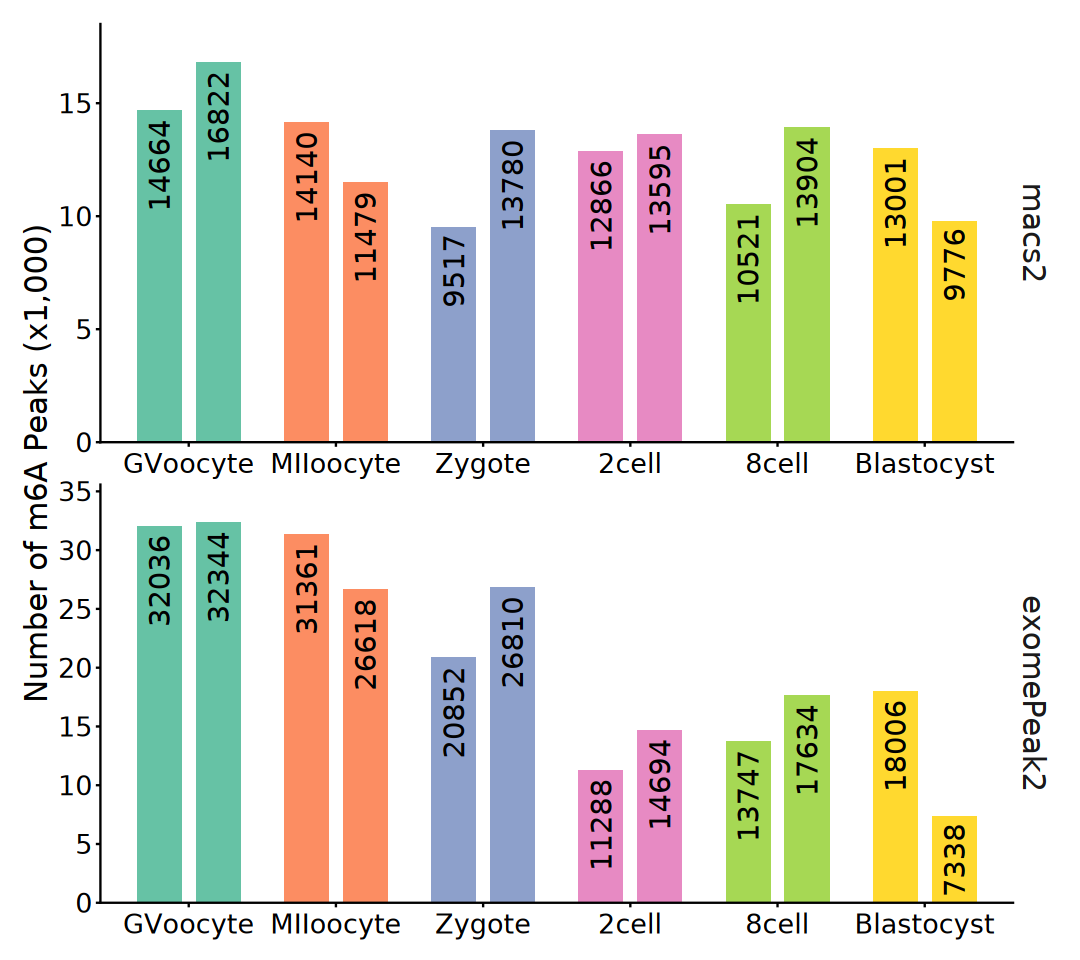

In [9]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(Stage, number, fill = Stage, group = Replicate)) +
    geom_bar(
        stat = "identity", width = 0.6, 
        position = position_dodge(width = 0.8)) +
    geom_text(
        aes(label = number), angle = 90, hjust = 1.1, vjust = 0.5, size = 6, 
        position = position_dodge(width = 0.8)) +
    facet_wrap(~ Method, ncol = 1, scales = "free", strip.position = "right") +
    scale_y_continuous(
        breaks = seq(0, 50000, 5000), labels = seq(0, 50, 5), 
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Number of m6A Peaks (x1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing.x = unit(0, "lines"), 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.position = "none", 
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 0, vjust = 0.5), 
        axis.text.y = element_text(size = 16))

## 3). Replicate Consistency

In [11]:
# ------------------------------------------------------------------------------
# Function: summarize_peak_overlaps
#
# Description:
# Summarize the overlap composition of peak sets across replicates.
#
# Arguments:
#   peaks_list : named list of GRanges.
#   peaks      : short names used for display and ordering.
#                Default: rep1, rep2, ..., repN.
# ------------------------------------------------------------------------------
summarize_peak_overlaps <- function(
    peaks_list, peaks = paste0("rep", seq_along(peaks_list)), 
    ignore.strand = TRUE) {

    names(peaks_list) <- peaks

    comb_levels <- unlist(
        lapply(seq_along(peaks), function(i) {
            combn(peaks, i, FUN = paste, collapse = "&")
        }), use.names = FALSE)

    ol <- lapply(peaks_list, function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
            ChIPpeakAnno::findOverlapsOfPeaks(
                ignore.strand = ignore.strand)

    ol$venn_cnt[, c(names(peaks_list), "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        dplyr::rename_with(~ peaks, .cols = names(peaks_list)) |>
        dplyr::rowwise() |>
        dplyr::mutate(
            Combination = {
                present <- peaks[c_across(dplyr::all_of(peaks)) == 1]
                if (length(present) == 0) {
                    NA_character_
                } else {
                    paste(present, collapse = "&")
                }
            }
        ) |>
        dplyr::ungroup() |>
        dplyr::mutate(
            Combination = factor(Combination, levels = comb_levels)) |>
        dplyr::filter(!is.na(Combination)) |>
        dplyr::select(Combination, Counts) |>
        as.data.frame()
}

In [ ]:
overlap_summary <- coldata |>
    split(~ Stage + Method, drop = TRUE) |>
    purrr::imap_dfr(function(df, group_name) {
        method <- unique(df$Method)
        group  <- unique(df$Stage)
        summarize_peak_overlaps(
            peaks_list[rownames(df)], ignore.strand = method == "macs2") |>
            mutate(Method = method, Group = group, .before = 1)
    })

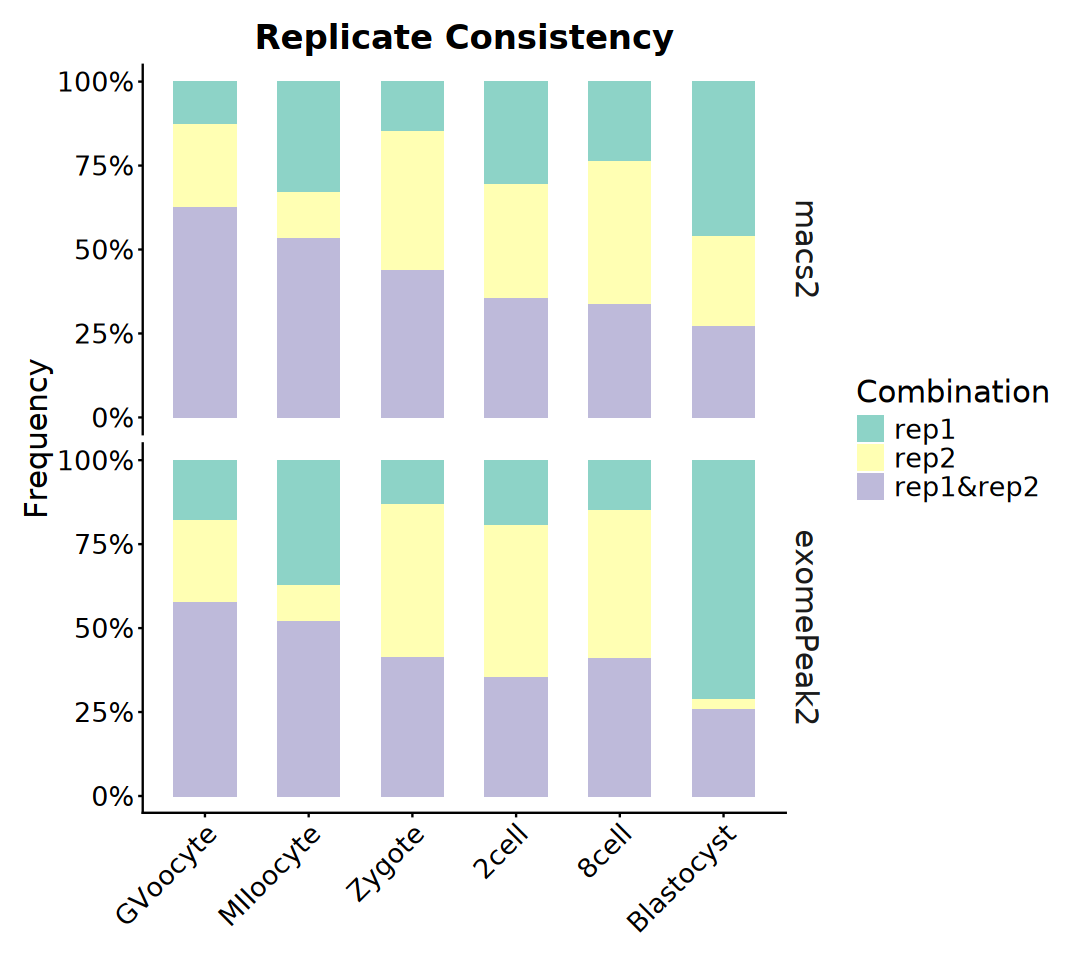

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

overlap_summary |> 
    mutate(Group = factor(Group, levels = levels(coldata$Stage))) |>
ggplot(aes(x = Group, y = Counts, fill = Combination)) +
    geom_bar(stat = "identity", position = "fill", width = 0.6) +
    scale_y_continuous(labels = scales::percent_format()) +
    scale_fill_brewer(palette = "Set3") +
    facet_wrap(~ Method, nrow = 2, strip.position = "right") +
    labs(title = "Replicate Consistency", x = NULL, y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 16))

## 4). Peak Annotation

In [23]:
suppressPackageStartupMessages(library(ChIPseeker))

In [24]:
# Annotate m6A peaks at transcript level
peaks_anno_list <- lapply(
    peaks_list, 
    annotatePeak, 
    TxDb = txdb, 
    tssRegion = c(0, 0), 
    level = "transcript", 
    sameStrand = TRUE, 
    genomicAnnotationPriority = c(
        "5UTR", "3UTR", "Exon", "Intron", 
        "Promoter", "Downstream", "Intergenic"), 
    verbose = FALSE
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Gen

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>."


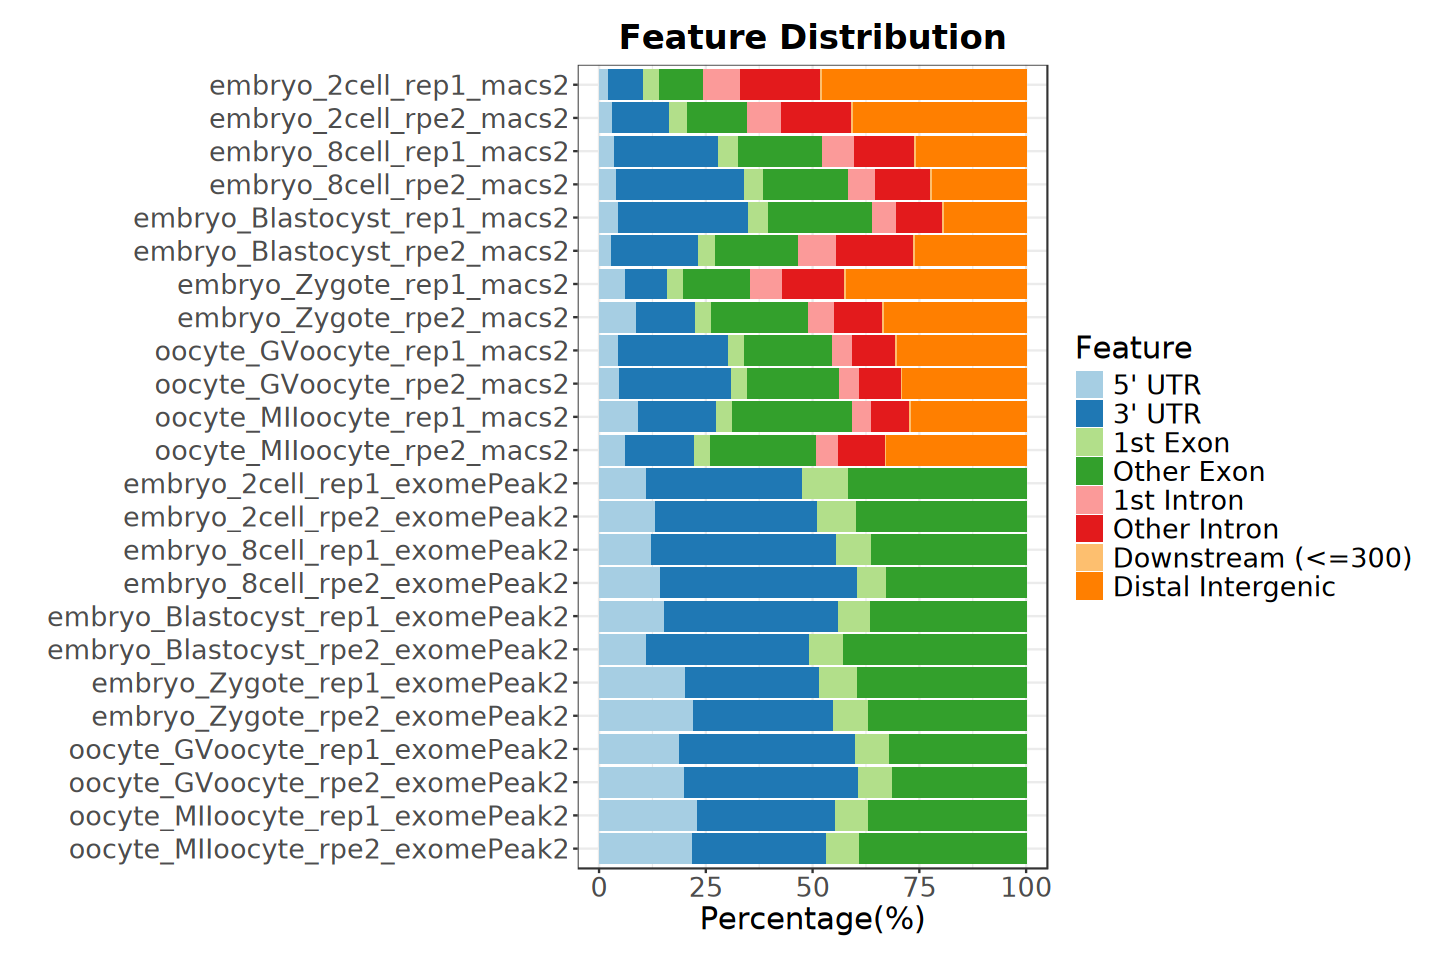

In [25]:
options(repr.plot.width = 12, repr.plot.height = 8)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [26]:
# Simplify transcript-region annotation
format_peak_annotation <- function(anno) {
    anno@anno |>
        as.data.frame() |>
        mutate(
            Category = case_when(
                grepl("5' UTR", annotation, fixed = TRUE) ~ "5' UTR",
                grepl("3' UTR", annotation, fixed = TRUE) ~ "3' UTR",
                grepl("Exon", annotation, fixed = TRUE) ~ "CDS",
                grepl("Intron", annotation, fixed = TRUE) ~ "Intron",
                TRUE ~ "Intergenic"
            )
        ) |>
        as("GRanges")
}

In [27]:
peaks_anno_list <- lapply(peaks_anno_list, format_peak_annotation)

In [28]:
# Prepare transcript biotype information
tx_info <- data.frame(
    transcript_id = as.character(gtf$transcript_id),
    gene_type = as.character(gtf$gene_type)
) |>
    filter(
        !is.na(transcript_id), transcript_id != "", 
        !is.na(gene_type), gene_type != "") |>
    distinct(transcript_id, .keep_all = TRUE)

In [29]:
# Collapse detailed GENCODE gene types into broader categories
collapse_gene_type <- function(x) {
    x <- as.character(x)
    case_when(
        is.na(x) | x == "" ~ NA_character_,
        grepl("pseudogene", x) ~ "pseudogene",
        x == "protein_coding" | 
            grepl("^(IG|TR)_.+_gene$", x) ~ "protein_coding",
        x == "lncRNA" ~ "lncRNA",
        x %in% c(
            "miRNA", "snRNA", "snoRNA", "scaRNA", "sRNA", "scRNA",
            "vault_RNA", "vaultRNA", "tRNA", "Mt_tRNA") ~ "small_RNA",
        x %in% c("rRNA", "Mt_rRNA") ~ "rRNA",
        TRUE ~ "other"
    )
}

In [30]:
# Add gene type to annotated peaks
add_gene_type <- function(gr) {
    idx <- match(gr$transcriptId, tx_info$transcript_id)
    gr$gene_type <- collapse_gene_type(tx_info$gene_type[idx])
    gr
}

In [31]:
peaks_anno_list <- lapply(peaks_anno_list, add_gene_type)

In [32]:
plot_df <- map_dfr(peaks_anno_list, ~ as.data.frame(.x), .id = "sample") |>
    mutate(gene_type = replace_na(gene_type, "unannotated")) |>
    count(sample, gene_type, name = "n") |>
    group_by(sample) |>
    mutate(percent = n / sum(n) * 100) |>
    ungroup() |>
    mutate(gene_type = factor(gene_type, levels = c(
        "protein_coding", "lncRNA", "small_RNA", "rRNA",
        "pseudogene", "other", "unannotated"))) |>
    mutate(sample = sub("oocyte_|embryo_", "", sample))

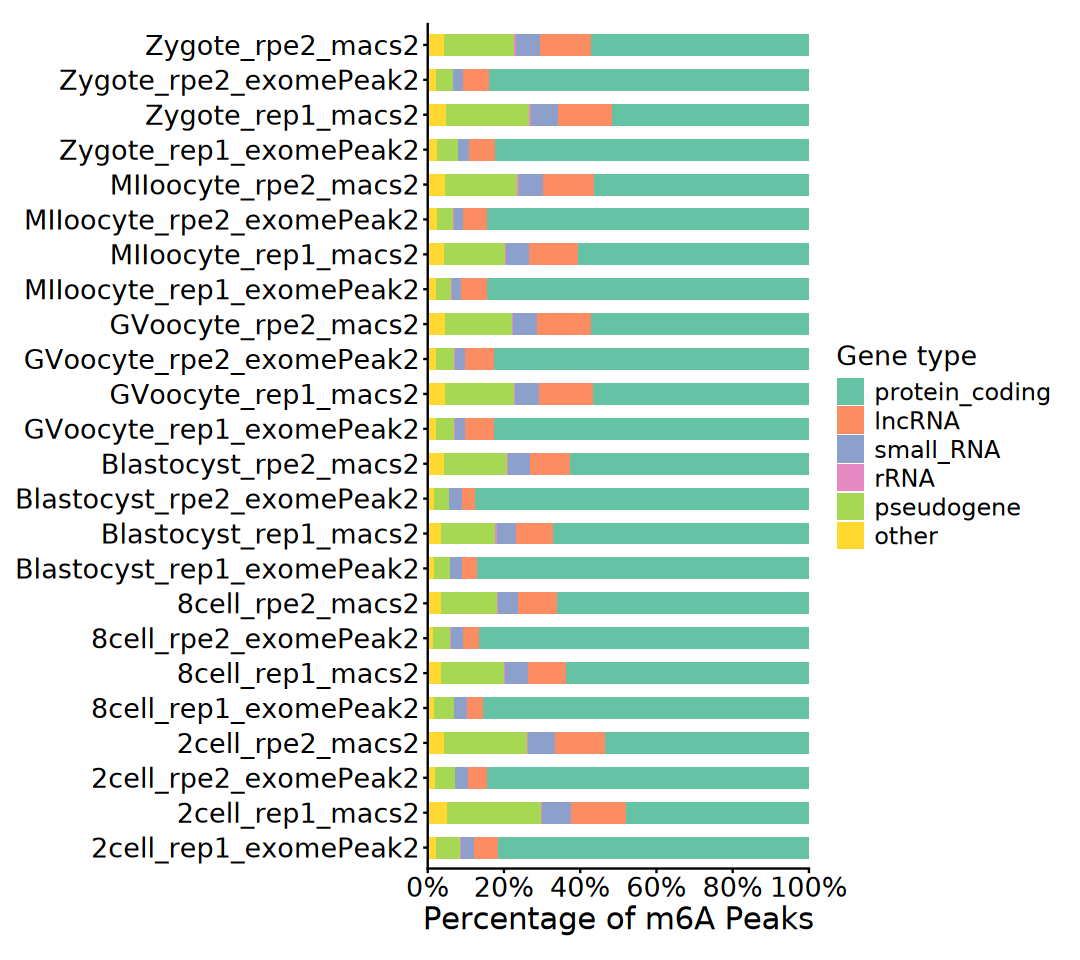

In [33]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(sample, percent, fill = gene_type)) +
    geom_bar(stat = "identity", width = 0.6) +
    scale_y_continuous(
        breaks = seq(0, 100, 20), labels = paste0(seq(0, 100, 20), "%"),
        expand = expansion(mult = c(0, 0))) +
    scale_fill_brewer(palette = "Set2") +
    coord_flip() +
    labs(x = NULL, y = "Percentage of m6A Peaks", fill = "Gene type") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 16),
        legend.text = element_text(size = 14),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Guitar Plot

In [60]:
suppressPackageStartupMessages(library(Guitar))

In [61]:
guitarTxdb <- makeGuitarTxdb(
    txdb, txpromoterLength = 0, txtailLength = 0,
    pltTxType =  "mrna", withTxContext = TRUE)

[1] "There are 142314 transcripts of 55298 genes in the genome."
[1] "total 142314 transcripts extracted ..."
[1] "total 98263 transcripts left after ambiguity filter ..."
[1] "total 98263 transcripts left after check chromosome validity ..."
[1] "total 16306 mRNAs left after component length filter ..."
[1] "total 47891 ncRNAs left after ncRNA length filter ..."
[1] "generate components for mRNA"
[1] "generate chiped transcriptome"
[1] "generate coverage checking ranges for mrna"


In [62]:
str(guitarTxdb$mrna$componentWidthAverage_pct)

 Named num [1:5] 0 0.126 0.46 0.414 0
 - attr(*, "names")= chr [1:5] "promoter" "utr5" "cds" "utr3" ...


In [63]:
txMrnaComponentProp <- guitarTxdb$mrna$componentWidthAverage_pct

In [64]:
# ~ 4 min
plot_guitar_dat <- GuitarPlot(
    txTxdb = txdb, 
    stGRangeLists = peaks_list, 
    headOrtail = FALSE, 
    enableCI = FALSE, 
    mapFilterTranscript = TRUE, 
    pltTxType = "mrna", 
    stGroupName = names(peaks_list)
)

[1] "20260918132309"
[1] "There are 142314 transcripts of 55298 genes in the genome."
[1] "total 142314 transcripts extracted ..."
[1] "total 98263 transcripts left after ambiguity filter ..."
[1] "total 98263 transcripts left after check chromosome validity ..."
[1] "total 16306 mRNAs left after component length filter ..."
[1] "total 47891 ncRNAs left after ncRNA length filter ..."
[1] "generate components for mRNA"
[1] "generate chiped transcriptome"
[1] "generate coverage checking ranges for mrna"
[1] "20260918132614"
[1] "sample 10 points for embryo_2cell_rep1_macs2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 4 out-of-bound ranges located on sequences
  ENSMUST00000144910.1, ENSMUST00000114184.7, ENSMUST00000034205.4, and
  ENSMUST00000114147.1. Note that ranges located on a sequence whose length is
  unknown (NA) or on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags of the
  underlying sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information."


[1] "sample 10 points for embryo_2cell_rpe2_macs2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 4 out-of-bound ranges located on sequences
  ENSMUST00000144910.1, ENSMUST00000114184.7, ENSMUST00000210781.1, and
  ENSMUST00000114147.1. Note that ranges located on a sequence whose length is
  unknown (NA) or on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags of the
  underlying sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information."


[1] "sample 10 points for embryo_8cell_rep1_macs2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 4 out-of-bound ranges located on sequences
  ENSMUST00000235795.1, ENSMUST00000106091.8, ENSMUST00000211248.1, and
  ENSMUST00000034205.4. Note that ranges located on a sequence whose length is
  unknown (NA) or on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags of the
  underlying sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information."


... (40 outputs left out)

[1] "sample 10 points for oocyte_MIIoocyte_rpe2_exomePeak2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 422 out-of-bound ranges located on sequences
  ENSMUST00000105393.2, ENSMUST00000001184.9, ENSMUST00000110082.10,
  ENSMUST00000001319.14, ENSMUST00000001724.11, ENSMUST00000002198.3,
  ENSMUST00000002436.10, ENSMUST00000002551.4, ENSMUST00000170051.7,
  ENSMUST00000004172.14, ENSMUST00000004200.8, ENSMUST00000040321.12,
  ENSMUST00000105465.7, ENSMUST00000133315.3, ENSMUST00000005606.7,
  ENSMUST00000005620.9, ENSMUST00000112184.9, ENSMUST00000006898.9,
  ENSMUST00000067692.12, ENSMUST00000007865.6, ENSMUST00000007921.8,
  ENSMUST00000009174.14, ENSMUST00000109399.8, ENSMUST00000059250.7,
  ENSMUST00000114147.1, ENSMUST00000015449.5, ENSMUST00000067620.11,
  ENSMUST00000165443.3, ENSMUST00000163272.1, ENSMUST00000017920.13,
  ENSMUST00000071465.8, ENSMUST00000103179.9, ENSMUST00000100705.10,
  ENSMUST00000166179.8, ENSMUST00000107364.7, ENSMUST00000019354.10,
  ENSMUST00000019917.5, ENSMUS

[1] "start figure plotting for mrna ..."


Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the Guitar package.
  Please report the issue to the authors."


In [70]:
plot_guitar_dat$data |> 
    left_join(
        coldata |> rownames_to_column("sample"), by = c("group" = "sample")) |>
    mutate(group = sub("oocyte_|embryo_", "", group)) |> head()

,x,density,group,Tissue,Stage,Replicate,Method
,<dbl>,<dbl>,<chr>,<fct>,<fct>,<fct>,<fct>
1,0.000000000,0.05290024,2cell_rep1_macs2,embryo,2cell,rep1,macs2
2,0.003921569,0.06238133,2cell_rep1_macs2,embryo,2cell,rep1,macs2
3,0.007843137,0.07261510,2cell_rep1_macs2,embryo,2cell,rep1,macs2
4,0.011764706,0.08341419,2cell_rep1_macs2,embryo,2cell,rep1,macs2
5,0.015686275,0.09465741,2cell_rep1_macs2,embryo,2cell,rep1,macs2
6,0.019607843,0.10618154,2cell_rep1_macs2,embryo,2cell,rep1,macs2


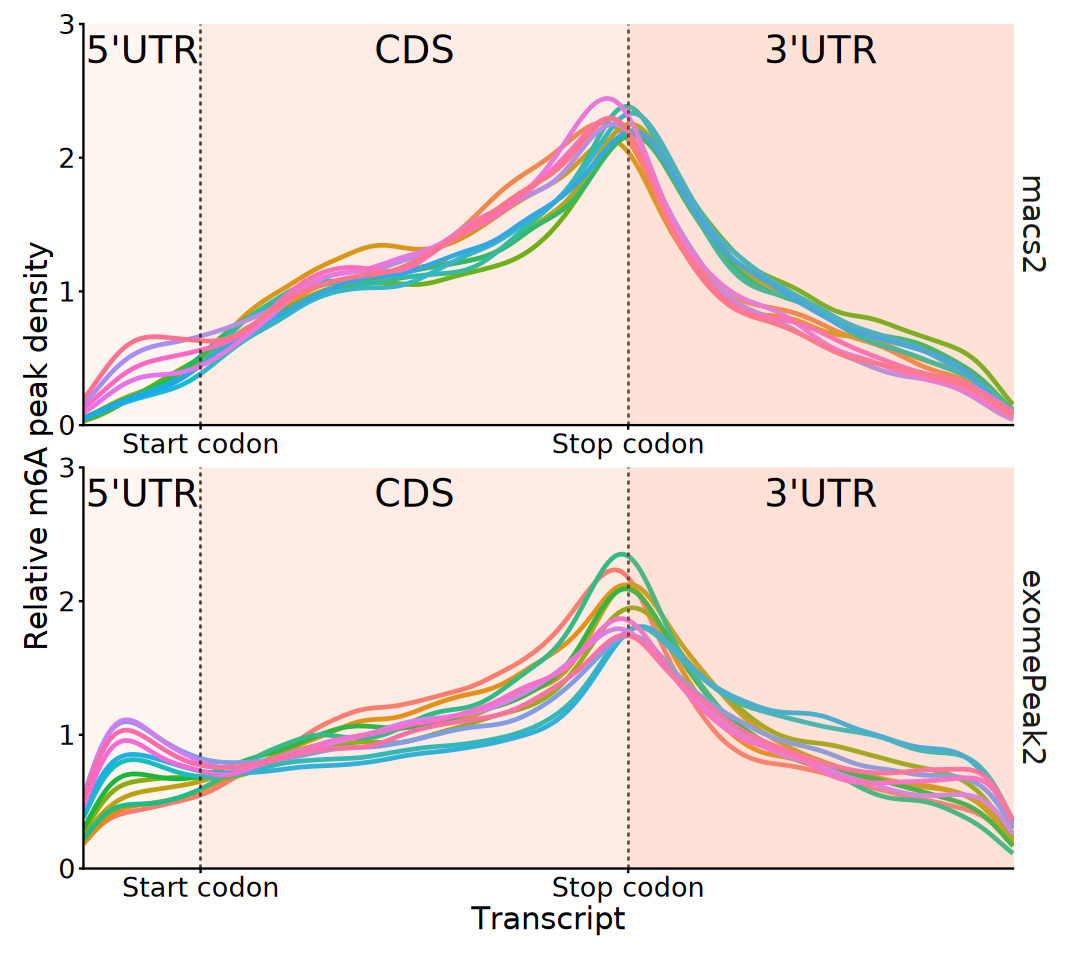

In [74]:
options(repr.plot.width = 9, repr.plot.height = 8)

plot_guitar_dat$data |> 
    left_join(
        coldata |> rownames_to_column("sample"), by = c("group" = "sample")) |>
    mutate(group = sub("oocyte_|embryo_", "", group)) |>
ggplot(aes(x = x, y = density, colour = group)) +
    geom_line(alpha = 1, linewidth = 1) +
    geom_vline(
        aes(xintercept = sum(txMrnaComponentProp[1:2])), linetype = "dashed") +
    geom_vline(
        aes(xintercept = sum(txMrnaComponentProp[1:3])), linetype = "dashed") +
    annotate(
        "rect", xmin = 0, xmax = sum(txMrnaComponentProp[1:2]), 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.1) +
    annotate(
        "rect", xmin = sum(txMrnaComponentProp[1:2]), 
        xmax = sum(txMrnaComponentProp[1:3]), 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.2) +
    annotate(
        "rect", xmin = sum(txMrnaComponentProp[1:3]), xmax = 1, 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.3) +
    annotate("text", x = 0.063, y = 3, label = "5'UTR", vjust = 1.4, size = 8) +
    annotate("text", x = 0.356, y = 3, label = "CDS", vjust = 1.4, size = 8) +
    annotate("text", x = 0.793, y = 3, label = "3'UTR", vjust = 1.4, size = 8) +
    facet_wrap(~ Method, ncol = 1, scales = "free", strip.position = "right") +
    scale_x_continuous(
        breaks = c(
            sum(txMrnaComponentProp[1:2]), sum(txMrnaComponentProp[1:3])), 
        labels = c("Start codon", "Stop codon"), expand = c(0, 0)) +
    scale_y_continuous(expand = c(0, 0)) +
    labs(x = "Transcript", y = "Relative m6A peak density") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing.x = unit(0, "lines"), 
        strip.placement = "outside", 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18),
        legend.position = "none",
        legend.position.inside = c(0.80, 0.65),
        legend.background = element_blank(),
        legend.key = element_rect(fill = NA),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 6). Peak Metagene

In [38]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(GenomicFeatures))
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [44]:
# Select the longest transcript of each gene
protein_coding_transcript <- transcriptLengths(
    txdb, with.cds_len = TRUE, with.utr5_len = TRUE, with.utr3_len = TRUE) |>
    as.data.frame() |>
    left_join(
        gtf |> as.data.frame() |> 
        dplyr::select(transcript_id, gene_type) |>
        distinct(), by = c("tx_name" = "transcript_id")) |>
    filter(gene_type == "protein_coding") |>
    arrange(gene_id, desc(tx_len), tx_name) |>
    distinct(gene_id, .keep_all = TRUE) |>
    filter(utr5_len >= 50, cds_len >= 100, utr3_len >= 100)

head(protein_coding_transcript)

,tx_id,tx_name,gene_id,nexon,tx_len,cds_len,utr5_len,utr3_len,gene_type
,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<chr>
1,25433,ENSMUST00000000001.4,ENSMUSG00000000001.4,9,3262,1062,141,2059,protein_coding
2,138774,ENSMUST00000000003.13,ENSMUSG00000000003.15,7,902,522,140,240,protein_coding
3,118306,ENSMUST00000000028.13,ENSMUSG00000000028.15,20,2143,1698,313,132,protein_coding
4,137430,ENSMUST00000112345.7,ENSMUSG00000000037.17,26,4847,2703,501,1643,protein_coding
5,88295,ENSMUST00000000049.5,ENSMUSG00000000049.11,8,1190,1035,51,104,protein_coding
6,88911,ENSMUST00000103015.3,ENSMUSG00000000056.7,11,4395,1386,72,2937,protein_coding


In [67]:
# Extract complete exon models for selected transcripts
exons_by_tx <- exonsBy(txdb, by = "tx", use.names = TRUE)
exons_by_tx <- exons_by_tx[protein_coding_transcript$tx_name]
exons_by_tx

GRangesList object of length 15301:
$ENSMUST00000000001.4
GRanges object with 9 ranges and 3 metadata columns:
      seqnames              ranges strand |   exon_id            exon_name
         <Rle>           <IRanges>  <Rle> | <integer>          <character>
  [1]     chr3 108145888-108146146      - |     95570 ENSMUSE00000334714.3
  [2]     chr3 108123795-108123837      - |     95569 ENSMUSE00000276500.1
  [3]     chr3 108123542-108123683      - |     95568 ENSMUSE00000276490.1
  [4]     chr3 108118301-108118458      - |     95567 ENSMUSE00000276482.1
  [5]     chr3 108115763-108115891      - |     95566 ENSMUSE00000565003.1
  [6]     chr3 108112473-108112602      - |     95565 ENSMUSE00000565001.1
  [7]     chr3 108111935-108112088      - |     95564 ENSMUSE00000565000.1
  [8]     chr3 108109403-108109612      - |     95563 ENSMUSE00000404895.1
  [9]     chr3 108107280-108109316      - |     95562 ENSMUSE00000363317.2
      exon_rank
      <integer>
  [1]         1
  [2]         2


In [88]:
peaks_list[1]

$embryo_2cell_rep1_macs2
GRanges object with 12866 ranges and 6 metadata columns:
          seqnames            ranges strand |                   name     score
             <Rle>         <IRanges>  <Rle> |            <character> <numeric>
      [1]     chr1   3613187-3614160      * | embryo_2cell_rep1_m6..      1383
      [2]     chr1   4679836-4679985      * | embryo_2cell_rep1_m6..        29
      [3]     chr1   4709693-4709842      * | embryo_2cell_rep1_m6..        29
      [4]     chr1   4758147-4758296      * | embryo_2cell_rep1_m6..        46
      [5]     chr1   4880117-4880636      * | embryo_2cell_rep1_m6..       176
      ...      ...               ...    ... .                    ...       ...
  [12862]     chrY 90737781-90738233      * | embryo_2cell_rep1_m6..       310
  [12863]     chrY 90738545-90738855      * | embryo_2cell_rep1_m6..       314
  [12864]     chrY 90812243-90812395      * | embryo_2cell_rep1_m6..       114
  [12865]     chrY 90813142-90813297      * | emb

In [69]:
# Map genomic m6A peaks to spliced transcript coordinates

map_peaks_to_transcripts <- function(peaks, exons_by_tx) {
    exons_flat <- unlist(exons_by_tx, use.names = FALSE)
    exon_tx <- rep(names(exons_by_tx), elementNROWS(exons_by_tx))
    mcols(exons_flat)$tx_name <- exon_tx

    # Peak-exon overlaps
    hits <- findOverlaps(peaks, exons_flat, ignore.strand = FALSE)

    if (length(hits) == 0L) return(GRanges())

    qh <- queryHits(hits)
    sh <- subjectHits(hits)

    # Keep only the exonic portion of each peak
    peak_fragments <- GRanges(
        seqnames = seqnames(exons_flat)[sh],
        ranges = pintersect(ranges(peaks)[qh], ranges(exons_flat)[sh]),
        strand = strand(exons_flat)[sh]
    )

    tx_hit <- mcols(exons_flat)$tx_name[sh]

    # Pair every peak fragment with its corresponding transcript model
    tx_models <- exons_by_tx[tx_hit]
    names(tx_models) <- tx_hit

    # Genomic coordinates -> transcript coordinates
    peak_tx <- pmapToTranscripts(
        peak_fragments, tx_models, ignore.strand = FALSE)

    # Coordinates are already oriented 5' -> 3' in transcript space,
    # therefore genomic strand is no longer required downstream.
    strand(peak_tx) <- "*"

    # Remove redundant/overlapping fragments in transcript space
    peak_tx <- reduce(peak_tx, ignore.strand = TRUE)

    peak_tx
}

In [93]:
names(peaks_list)[17]

[1] "embryo_Blastocyst_rep1_exomePeak2"

In [94]:
peaks <- peaks_list[[17]]

peak_tx <- map_peaks_to_transcripts(peaks, exons_by_tx)

peak_tx

GRanges object with 12298 ranges and 0 metadata columns:
                      seqnames    ranges strand
                         <Rle> <IRanges>  <Rle>
      [1] ENSMUST00000000001.4 1188-1737      *
      [2] ENSMUST00000000080.7   368-867      *
      [3] ENSMUST00000000080.7 1160-1184      *
      [4] ENSMUST00000000080.7 1260-1709      *
      [5] ENSMUST00000000080.7 2435-2784      *
      ...                  ...       ...    ...
  [12294] ENSMUST00000233465.1 2025-2249      *
  [12295] ENSMUST00000233465.1 2900-2949      *
  [12296] ENSMUST00000233465.1 2975-2999      *
  [12297] ENSMUST00000233465.1 3025-3099      *
  [12298] ENSMUST00000233465.1 3175-3274      *
  -------
  seqinfo: 4428 sequences from an unspecified genome

In [95]:
# Define 5'UTR, CDS and 3'UTR in transcript coordinates
tx_region <- protein_coding_transcript |>
    transmute(
        gene_id, 
        tx_name, 
        utr5_start = 1L,
        utr5_end   = as.integer(utr5_len),
        cds_start  = as.integer(utr5_len + 1L),
        cds_end    = as.integer(utr5_len + cds_len),
        utr3_start = as.integer(utr5_len + cds_len + 1L),
        utr3_end   = as.integer(utr5_len + cds_len + utr3_len)
    )

utr5_target <- GRanges(
    seqnames = tx_region$tx_name,
    ranges = IRanges(start = tx_region$utr5_start, end = tx_region$utr5_end),
    strand = "*"
)

cds_target <- GRanges(
    seqnames = tx_region$tx_name,
    ranges = IRanges(start = tx_region$cds_start, end = tx_region$cds_end),
    strand = "*"
)

utr3_target <- GRanges(
    seqnames = tx_region$tx_name,
    ranges = IRanges(start = tx_region$utr3_start, end = tx_region$utr3_end),
    strand = "*"
)

names(utr5_target) <- tx_region$tx_name
names(cds_target)  <- tx_region$tx_name
names(utr3_target) <- tx_region$tx_name

In [96]:
# Normalize m6A peak occupancy to 10 + 20 + 20 transcript windows
mat_5utr <- normalizeToMatrix(
    signal = peak_tx, target = utr5_target, extend = 0, target_ratio = 1,
    k = 10, background = 0, mean_mode = "absolute", smooth = FALSE
)
mat_cds <- normalizeToMatrix(
    signal = peak_tx, target = cds_target, extend = 0, target_ratio = 1,
    k = 20, background = 0, mean_mode = "absolute", smooth = FALSE
)
mat_3utr <- normalizeToMatrix(
    signal = peak_tx, target = utr3_target, extend = 0, target_ratio = 1,
    k = 20, background = 0, mean_mode = "absolute", smooth = FALSE
)

In [97]:
mat <- cbind(
    as.matrix(mat_5utr),
    as.matrix(mat_cds),
    as.matrix(mat_3utr)
)

colnames(mat) <- c(
    paste0("5UTR_", seq_len(10)),
    paste0("CDS_",  seq_len(20)),
    paste0("3UTR_", seq_len(20))
)

In [98]:
norm_mat <- as.normalizedMatrix(
    mat, k_upstream = 10, k_target = 20, k_downstream = 20, extend = c(1, 1),
    signal_name = "m6A peak", target_name = "CDS", background = 0
)

In [105]:
col_fun <- colorRamp2(c(0, 1), c("white", "#2E8B57"))

ht <- EnrichedHeatmap(
    norm_mat, 
    name = "m6A peak",
    col = col_fun,
    cluster_rows = FALSE,
    show_row_names = FALSE,
    use_raster = TRUE,
    pos_line = TRUE,
    pos_line_gp = gpar(col = "grey40", lty = 2),
    axis_name = c("5' UTR", "CDS start", "CDS end", "3' UTR"),
    top_annotation = HeatmapAnnotation(
        enrichment = anno_enriched(
            gp = gpar(col = "black", lwd = 2),
            axis_param = list(side = "right"))),
    heatmap_legend_param = list(title = "m6A peak")
)

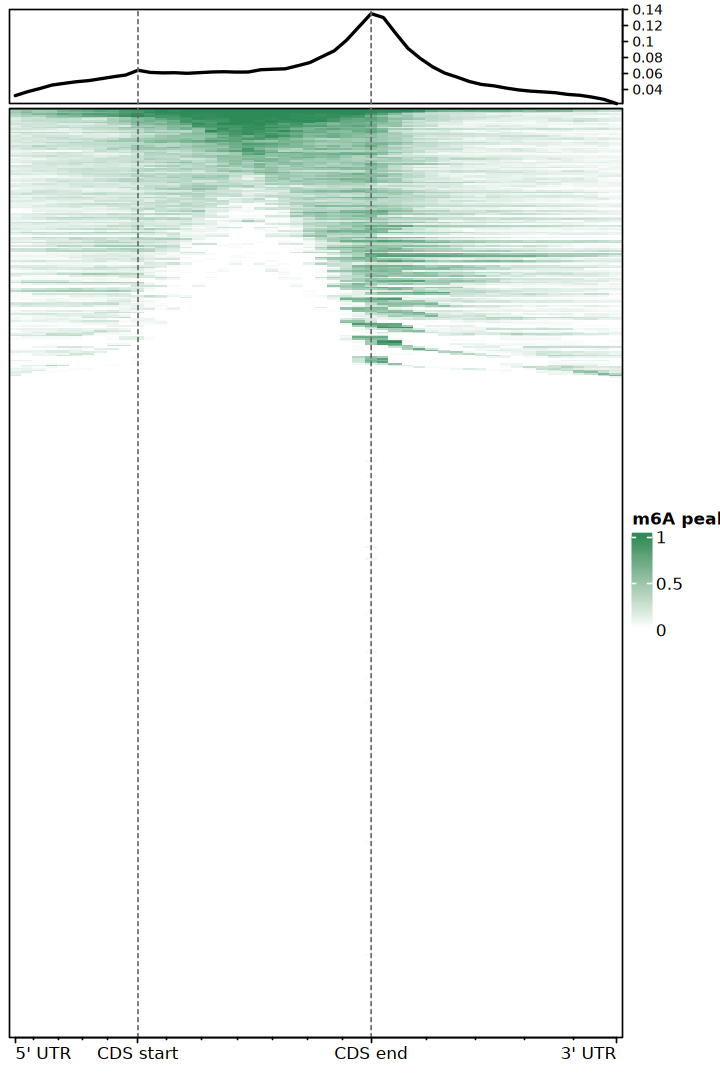

In [106]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(ht)

In [ ]:
# Get all exons of representative transcripts
exons_by_tx <- exonsBy(txdb, by = "tx", use.names = TRUE)
exons_by_tx <- exons_by_tx[tx_info$tx_name]

# Keep transcript information in exactly the same order
tx_info <- tx_info |>
    filter(tx_name %in% names(exons_by_tx)) |>
    arrange(match(tx_name, names(exons_by_tx)))

exons_by_tx <- exons_by_tx[tx_info$tx_name]

In [ ]:
# Build genomic-to-transcript exon map
map_peaks_to_transcripts <- function(
    peaks, exons_by_tx, tx_info, ignore_strand = FALSE) {

    # Use peak centers to represent m6A peak positions
    peak_center <- resize(peaks, width = 1, fix = "center")
    peak_center$peak_id <- seq_along(peak_center)

    # Map genomic coordinates to spliced transcript coordinates
    mapped <- mapToTranscripts(
        peak_center, exons_by_tx, ignore.strand = ignore_strand)

    mapped_df <- as.data.frame(mapped) |>
        transmute(
            transcript_id = as.character(seqnames), tx_position = start,
            peak_id = mcols(mapped)$xHits) |>
        left_join(
            tx_info |>
                dplyr::select(
                    transcript_id = tx_name, gene_id, 
                    utr5_len, cds_len, utr3_len),
            by = "transcript_id")
    
    mapped_df
}

In [ ]:
# Assign mapped peaks to transcript regions
assign_transcript_region <- function(mapped_df) {
    mapped_df |> 
        mutate(
            region = case_when(
                tx_position <= utr5_len ~ "5UTR",
                tx_position <= utr5_len + cds_len ~ "CDS",
                tx_position <= utr5_len + cds_len + utr3_len ~ "3UTR",
                TRUE ~ NA_character_
            ),
            region_position = case_when(
                region == "5UTR" ~ tx_position,
                region == "CDS" ~ tx_position - utr5_len,
                region == "3UTR" ~ tx_position - utr5_len - cds_len
            ),
            region_length = case_when(
                region == "5UTR" ~ utr5_len,
                region == "CDS" ~ cds_len,
                region == "3UTR" ~ utr3_len
            )) |>
        filter(!is.na(region))
}

In [ ]:
# Normalize transcript positions into metagene bins
assign_metagene_bins <- function(
    mapped_df, bins = c("5UTR" = 10, "CDS" = 20, "3UTR" = 20)) {
    mapped_df |>
        mutate(
            n_bin = bins[region],
            bin = pmin(ceiling(region_position / region_length * n_bin), n_bin),
            metagene_bin = case_when(
                region == "5UTR" ~ bin,
                region == "CDS" ~ bins["5UTR"] + bin,
                region == "3UTR" ~ bins["5UTR"] + bins["CDS"] + bin
            )
        )
}

In [ ]:
# Construct transcript-by-bin matrix

make_metagene_matrix <- function(
    peaks, exons_by_tx, tx_info, bins = c("5UTR" = 10, "CDS" = 20, "3UTR" = 20), 
    ignore_strand = FALSE) {

    mapped_df <- map_peaks_to_transcripts(
        peaks, exons_by_tx, tx_info, ignore_strand = ignore_strand) |>
        assign_transcript_region() |>
        assign_metagene_bins(bins = bins)

    n_bins <- sum(bins)

    mat <- matrix(
        0, nrow = nrow(tx_info), ncol = n_bins,
        dimnames = list(tx_info$tx_name, seq_len(n_bins))
    )

    peak_count <- mapped_df |>
        count(transcript_id, metagene_bin, name = "n")

    row_idx <- match(peak_count$transcript_id, rownames(mat))

    mat[cbind(row_idx, peak_count$metagene_bin)] <- peak_count$n

    colnames(mat) <- c(
        paste0("5UTR_", seq_len(bins["5UTR"])),
        paste0("CDS_", seq_len(bins["CDS"])),
        paste0("3UTR_", seq_len(bins["3UTR"]))
    )

    mat
}

In [ ]:
metagene_mat_list <- lapply(
    peaks_list, make_metagene_matrix, 
    exons_by_tx = exons_by_tx, tx_info = tx_info
)

In [ ]:
sample_order <- coldata |>
    rownames_to_column("sample") |>
    arrange(Method, Genotype, Replicate) |>
    pull(sample)

metagene_mat_list <- metagene_mat_list[sample_order]

In [ ]:
# Calculate mean peak density across transcripts
profile_df <- map_dfr(
    metagene_mat_list, ~ data.frame(
        bin = seq_len(ncol(.x)),
        density = colMeans(.x)
    ), .id = "sample"
) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

head(profile_df)

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(profile_df, aes(bin, density, group = sample)) +
    geom_line(aes(color = Genotype, linetype = Replicate), linewidth = 1.2) +
    geom_vline(xintercept = c(10.5, 30.5), linetype = "dashed") +
    scale_x_continuous(
        breaks = c(1, 10, 30, 50),
        labels = c("5' end", "CDS start", "CDS end", "3' end")) +
    scale_color_brewer(palette = "Set2") +
    facet_wrap(~ Method, nrow = 2) +
    labs(
        x = NULL, y = "Mean m6A peak density", 
        color = "Genotype", linetype = "Replicate") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        # panel.spacing.x = unit(0, "lines"),
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 16),
        legend.text = element_text(size = 14),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 14),
        axis.text.y = element_text(size = 16))

In [ ]:
metagene_norm_list <- lapply(metagene_mat_list, function(mat) {
    as.normalizedMatrix(
        mat, 
        k_upstream = 10,
        k_target = 20,
        k_downstream = 20,
        extend = c(1, 1),
        signal_name = "m6A peak",
        target_name = "CDS"
    )
})

In [ ]:
mean_signal <- Reduce("+", lapply(metagene_mat_list, rowSums)) / 
    length(metagene_mat_list)

row_order <- order(mean_signal, decreasing = TRUE)

In [ ]:
unified_cols <- circlize::colorRamp2(c(0, 1), c("white", "#08519C"))

signal_lgd <- Legend(col_fun = unified_cols, title = "FPKM")

In [ ]:
ht_list <- lapply(seq_along(metagene_norm_list), function(i) {
    sample <- sub("HCCLM3_ALKBH5_", "", names(metagene_norm_list)[i])

    EnrichedHeatmap(
        metagene_norm_list[[i]],
        name = sample,
        column_title = sample,
        col = unified_cols,
        row_order = row_order,
        cluster_rows = FALSE,
        show_row_names = FALSE,
        show_heatmap_legend = FALSE,
        axis_name = c("5' end", "CDS-S", "CDS-E", "3' end"), 
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = "#df0d0d"), 
                axis_param = list(gp = gpar(fontsize = 10))), 
            height = unit(3, "cm"), 
            show_legend = FALSE), 
        use_raster = TRUE)
})

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

draw(
    Reduce(`+`, ht_list[1:4]), 
    heatmap_legend_side = "right", 
    annotation_legend_list = list(signal_lgd),
    ht_gap = unit(10, "mm")
)

# 4. Transcriptome-wide Landscape

## 1). PCA

In [110]:
suppressPackageStartupMessages(library(DESeq2))

In [111]:
raw_counts <- file.path(data_dir, "08_counts", "featureCounts.all.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 55335    32

In [ ]:
coldata <- data.frame(sample = names(peaks_list)) |>
    mutate(
        .parts = str_split(sample, "_"), 
        Tissue = map_chr(.parts, ~ .x[1]) |> 
            factor(levels = c("oocyte", "embryo")), 
        Stage = map_chr(.parts, ~ .x[2]) |>
            factor(levels = c(
                "GVoocyte", "MIIoocyte", "Zygote", 
                "2cell", "8cell", "Blastocyst")),  
        Replicate = map_chr(.parts, ~ .x[3]) |> factor(),
        Assay = map_chr(.parts, ~ .x[4]) |> 
            factor(levels = c("m6A", "Input"))
    ) |>
    dplyr::select(-.parts) |>
    column_to_rownames("sample")

head(coldata)

In [113]:
coldata <- data.frame(sample = colnames(raw_counts)) |>
    filter(str_detect(sample, fixed("rep"))) |>
    mutate(
        .parts = str_split(sample, "_"), 
        Tissue = map_chr(.parts, ~ .x[1]) |> 
            factor(levels = c("oocyte", "embryo")), 
        Stage = map_chr(.parts, ~ .x[2]) |>
            factor(levels = c(
                "GVoocyte", "MIIoocyte", "Zygote", 
                "2cell", "8cell", "Blastocyst")),  
        Replicate = map_chr(.parts, ~ .x[3]) |> factor(),
        Assay = map_chr(.parts, ~ .x[4]) |> 
            factor(levels = c("m6A", "Input"))
    ) |>
    dplyr::select(-.parts) |>
    arrange(Stage, Replicate, Assay) |>
    column_to_rownames("sample")

In [114]:
coldata

,Tissue,Stage,Replicate,Assay
,<fct>,<fct>,<fct>,<fct>
oocyte_GVoocyte_rep1_m6A,oocyte,GVoocyte,rep1,m6A
oocyte_GVoocyte_rep1_Input,oocyte,GVoocyte,rep1,Input
oocyte_GVoocyte_rep2_m6A,oocyte,GVoocyte,rep2,m6A
oocyte_GVoocyte_rep2_Input,oocyte,GVoocyte,rep2,Input
oocyte_MIIoocyte_rep1_m6A,oocyte,MIIoocyte,rep1,m6A
oocyte_MIIoocyte_rep1_Input,oocyte,MIIoocyte,rep1,Input
oocyte_MIIoocyte_rep2_m6A,oocyte,MIIoocyte,rep2,m6A
oocyte_MIIoocyte_rep2_Input,oocyte,MIIoocyte,rep2,Input
embryo_Zygote_rep1_m6A,embryo,Zygote,rep1,m6A


In [ ]:
anno_gene <- raw_counts |> 
    dplyr::select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [ ]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    dplyr::select(any_of(rownames(coldata))) |>
    as.matrix()

In [ ]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Genotype)
dds

In [ ]:
keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dds <- dds[keep, ]

In [ ]:
rld <- rlog(dds, blind = FALSE)
norm_vs <- assay(rld)

In [ ]:
pca_res <- plotPCA(
    rld, intgroup = c("Genotype", "Assay"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Genotype, shape = Assay), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# *Reference